# Summative Lab – Analytics Firm Clients: Customer Reviews Analysis

This notebook works through the three parts of the lab using a single shared dataset: `amazon_reviews_lab.csv`, a set of Amazon product reviews.

1. **NLP**
2. **Time Series**
3. **Neural Networks**

## Part 1: Natural Language Processing (NLP)

In this section we clean and preprocess review text, explore frequent words and bigrams, and visualize key language patterns in the dataset.

In [1]:
# Imports
import pandas as pd                      # load and manipulate the review data as a DataFrame
import numpy as np                        # random seed control
import matplotlib.pyplot as plt           # bar charts for word/bigram frequency
import re                                 # regex, used to strip URLs from review text
import string                             # string.punctuation, used to strip punctuation
from collections import Counter           # tally word/bigram frequencies

import nltk
from nltk.tokenize import word_tokenize   # split cleaned text into individual word tokens
from nltk.corpus import stopwords         # common words ("the", "and", ...) to filter out
from nltk.stem import WordNetLemmatizer   # reduce words to their dictionary root form
from nltk.util import ngrams              # build bigrams (2-word sequences) from a token list

# Download the NLTK data files these tools depend on (tokenizer models, stopword list, lemmatizer dictionary)
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

np.random.seed(42)  # reproducibility for anything downstream that samples randomly

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [2]:
# Load the dataset
df = pd.read_csv('amazon_reviews_lab.csv')

print(f"Dataset shape: {df.shape}")
print("\nRating distribution:")
print(df['rating'].value_counts().sort_index())
print("\nSentiment label distribution:")
print(df['sentiment_label'].value_counts())
df.head(10)

Dataset shape: (997, 9)

Rating distribution:
rating
1     87
2     48
3     94
4    188
5    580
Name: count, dtype: int64

Sentiment label distribution:
sentiment_label
positive    768
negative    135
neutral      94
Name: count, dtype: int64


,product_id,rating,review_text,review_summary,review_time_raw,unix_review_time,timestamp,sentiment_label,review_length_words
0,6301977173,2,This film is definitely not for anyone who is ...,The best of Mark Twain's work - left out!,"05 12, 2000",9.580896e+08,2000-05-12,negative,302
1,6301977173,5,This movie was playing at Radio City Music Hal...,The best Tom Sawyer i ever saw.,"08 26, 2002",1.030320e+09,2002-08-26,positive,168
2,6301977173,1,I would love to buy this movie as I have been ...,Why no Widescreen?,"08 6, 2005",1.123286e+09,2005-08-06,negative,60
3,6301977173,1,The advertisment for this DVD on Amazon was in...,False advertising on this DVD,"09 11, 2005",1.126397e+09,2005-09-11,negative,104
4,9575871979,5,I bought some of these to try with a light usi...,Work GREAT!!,"10 15, 2007",1.192406e+09,2007-10-15,positive,60
5,0972683275,4,"For the money you can't go wrong. Yes, it has ...",can't beat it for the price,"02 19, 2008",1.203379e+09,2008-02-19,positive,44
6,6301977173,4,I hadn't heard of this 1973 movie version of t...,Take a Gander as Tom Sawyer Sings,"05 6, 2008",1.210032e+09,2008-05-06,positive,324
7,9575871979,4,I've had this kit for a few months now and hav...,Good Kit For the Price.,"12 19, 2008",1.229645e+09,2008-12-19,positive,478
8,9043413585,4,"Very fast, dependable OS (way better than the ...",Very good ppc,"01 4, 2009",1.231027e+09,2009-01-04,positive,43
9,9043413585,3,The Dell Axim X30 624 Mhz was released in 2004...,A Few Serious Problems,"02 5, 2009",1.233792e+09,2009-02-05,neutral,252


The dataset has 997 reviews across 9 columns. Ratings skew heavily positive: 580 five-star and 188 four-star reviews versus only 87 one-star and 48 two-star reviews. This imbalance matters for everything that follows: word frequencies will be dominated by whatever positive reviewers say, and Part 3's classifier will need explicit handling (class weights) to avoid just learning to predict "positive" for everything.

**Note on `sentiment_label`:** cross-checking this column against `rating` shows it's a deterministic mapping: ratings 1–2 map to `negative`, 3 to `neutral`, and 4–5 to `positive`. That's useful context for Part 3: it means `sentiment_label` is a coarser, 3-class version of the same signal in `rating`, not an independently-labeled column.

In [3]:
# Preprocessing tools
stop_words = set(stopwords.words('english'))  # set lookup is O(1), much faster than list lookup when
                                                 # filtering thousands of tokens
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    """Lowercase, strip URLs/punctuation, tokenize, keep alphabetic tokens,
    remove stopwords, and lemmatize. Returns a list of cleaned tokens."""
    text = text.lower()                                          # normalize case so "Great" and "great" count as the same word
    text = re.sub(r'http\S+|www\.\S+', '', text)                 # strip URLs before tokenizing so they don't leave junk tokens
    text = text.translate(str.maketrans('', '', string.punctuation))  # drop punctuation (periods, commas, etc.)
    tokens = word_tokenize(text)                                 # split into individual word tokens
    tokens = [t for t in tokens if t.isalpha()]                  # drop pure numbers / leftover symbols, keep words only
    tokens = [t for t in tokens if t not in stop_words]          # drop low-information words ("the", "is", "and", ...)
    tokens = [lemmatizer.lemmatize(t) for t in tokens]           # collapse inflected forms ("batteries" -> "battery") so frequency
                                                                   # counts aren't split across variants of the same word
    return tokens

# Apply preprocessing to the review text column
df['processed_tokens'] = df['review_text'].apply(preprocess_text)
df[['review_text', 'processed_tokens']].head(2)

,review_text,processed_tokens
0,This film is definitely not for anyone who is ...,"[film, definitely, anyone, especially, fond, i..."
1,This movie was playing at Radio City Music Hal...,"[movie, playing, radio, city, music, hall, bac..."


In [4]:
# --- Validating preprocessing quality ---
# Before trusting frequency counts built on `processed_tokens`, check what the pipeline
# is actually doing to the text: how much volume it removes, and whether a raw example
# review vs. its cleaned tokens still look like faithful representations of the same review.

sample_idx = 0
raw_review = df.loc[sample_idx, 'review_text']
cleaned_tokens = df.loc[sample_idx, 'processed_tokens']

print("RAW REVIEW (first 300 chars):")
print(raw_review[:300])
print("\nCLEANED TOKENS (first 25):")
print(cleaned_tokens[:25])

# Quantify how much text volume preprocessing removes, and how vocabulary shrinks
df['raw_word_count'] = df['review_text'].str.split().str.len()
df['cleaned_token_count'] = df['processed_tokens'].apply(len)

raw_vocab = set(w.lower().strip(string.punctuation) for review in df['review_text'] for w in review.split())
cleaned_vocab = set(t for doc in df['processed_tokens'] for t in doc)

avg_retention = (df['cleaned_token_count'] / df['raw_word_count']).mean()

print(f"\nAverage raw words per review:      {df['raw_word_count'].mean():.1f}")
print(f"Average cleaned tokens per review: {df['cleaned_token_count'].mean():.1f}")
print(f"Average token retention rate:      {avg_retention:.1%}")
print(f"Raw vocabulary size (rough, unlemmatized): {len(raw_vocab)}")
print(f"Cleaned vocabulary size (lemmatized, stopwords removed): {len(cleaned_vocab)}")
print(f"Vocabulary reduction: {(1 - len(cleaned_vocab) / len(raw_vocab)):.1%}")

RAW REVIEW (first 300 chars):
This film is definitely not for anyone who is especially fond of the independent, delightfully manipulative and clever boy who was the brain child of Samuel Clemens's classic.As one example, the book has great fun with the scenes involving Aunt Polly, a simple minded soul who thinks herself quite cl

CLEANED TOKENS (first 25):
['film', 'definitely', 'anyone', 'especially', 'fond', 'independent', 'delightfully', 'manipulative', 'clever', 'boy', 'brain', 'child', 'samuel', 'clemens', 'classicas', 'one', 'example', 'book', 'great', 'fun', 'scene', 'involving', 'aunt', 'polly', 'simple']

Average raw words per review:      146.4
Average cleaned tokens per review: 72.4
Average token retention rate:      49.1%
Raw vocabulary size (rough, unlemmatized): 10494
Cleaned vocabulary size (lemmatized, stopwords removed): 8587
Vocabulary reduction: 18.2%


**Validating preprocessing quality, and why it matters downstream.** The sample review above keeps its recognizable content words after cleaning (product names, opinions, features) while losing filler, that's the qualitative check. The quantitative check shows the pipeline is doing substantial, not superficial, work: on average only about **49% of raw words survive cleaning**, the other half are stopwords, punctuation-only tokens, or non-alphabetic noise, and the vocabulary shrinks by roughly **18%** once lemmatization collapses inflected forms together (e.g. "work"/"works"/"working" -> "work"). Losing half the raw word count sounds aggressive, but stopwords alone ("the", "a", "and", "is", ...) typically account for 40-50% of running text in English, so this retention rate is in the expected range for a stopword-removal + alpha-filter pipeline, not a sign of over-cleaning.

This matters for both downstream tasks in this notebook, in opposite ways:
- **For the Part 1 frequency/bigram counts**, a smaller, lemmatized vocabulary is exactly what we want, without lemmatization, `"work"`, `"works"`, and `"working"` would each get their own bucket and dilute the true frequency of the underlying concept, making the top-words list less informative.
- **For the Part 3 TF-IDF + neural network step**, the same shrinkage is a double-edged sword: fewer, cleaner tokens means less noise for the vectorizer to spend features on, but over-aggressive cleaning on a small dataset (997 reviews) risks collapsing away the subtle word choices that might separate `neutral` from `positive` reviews. That tradeoff is worth keeping in mind.

In [5]:
# Combine all tokens across the corpus for frequency analysis
all_tokens = [token for doc in df['processed_tokens'] for token in doc]
print(f"Total tokens after preprocessing: {len(all_tokens)}")

word_counter = Counter(all_tokens)          # tallies occurrences of every token in one pass
top_words = word_counter.most_common(20)    # 20 highest-frequency tokens, sorted descending
top_words

Total tokens after preprocessing: 72140


[('nook', 1509),
 ('book', 913),
 ('one', 569),
 ('kindle', 561),
 ('screen', 496),
 ('like', 459),
 ('read', 454),
 ('work', 446),
 ('get', 424),
 ('great', 422),
 ('use', 420),
 ('tablet', 419),
 ('tv', 416),
 ('device', 381),
 ('would', 378),
 ('good', 330),
 ('bn', 321),
 ('time', 318),
 ('also', 317),
 ('well', 305)]

Across all 997 reviews, preprocessing produces 72,140 tokens total. The top single words, `nook`, `book`, `kindle`, `screen`, `tablet`, `device`, `bn` (Barnes & Noble's own abbreviation), already show this is a dataset of e-reader/tablet reviews rather than general merchandise, well before any bigram or sentiment analysis is applied.

In [6]:
# Bigram frequency analysis: 2-word sequences often carry more meaning than single words
# (e.g. "battery life" vs. the words "battery" and "life" counted separately)
bigram_counter = Counter(ngrams(all_tokens, 2))
top_bigrams = bigram_counter.most_common(15)
top_bigrams

[(('barnes', 'noble'), 152),
 (('nook', 'color'), 127),
 (('battery', 'life'), 87),
 (('touch', 'screen'), 81),
 (('sd', 'card'), 80),
 (('nook', 'hd'), 74),
 (('work', 'great'), 63),
 (('nook', 'tablet'), 63),
 (('work', 'well'), 57),
 (('read', 'book'), 55),
 (('kindle', 'fire'), 55),
 (('wall', 'mount'), 51),
 (('simple', 'touch'), 44),
 (('android', 'tablet'), 39),
 (('customer', 'service'), 38)]

Bigrams sharpen that picture with concrete product and feature language: `barnes noble` (152) and `nook color` (127) are the two most common two-word phrases, followed by feature-specific pairs like `battery life` (87), `touch screen` (81), and `sd card` (80). These are exactly the kind of terms a support-routing system would want to key on, since they point to a specific product line or a specific hardware complaint rather than a generic sentiment word.

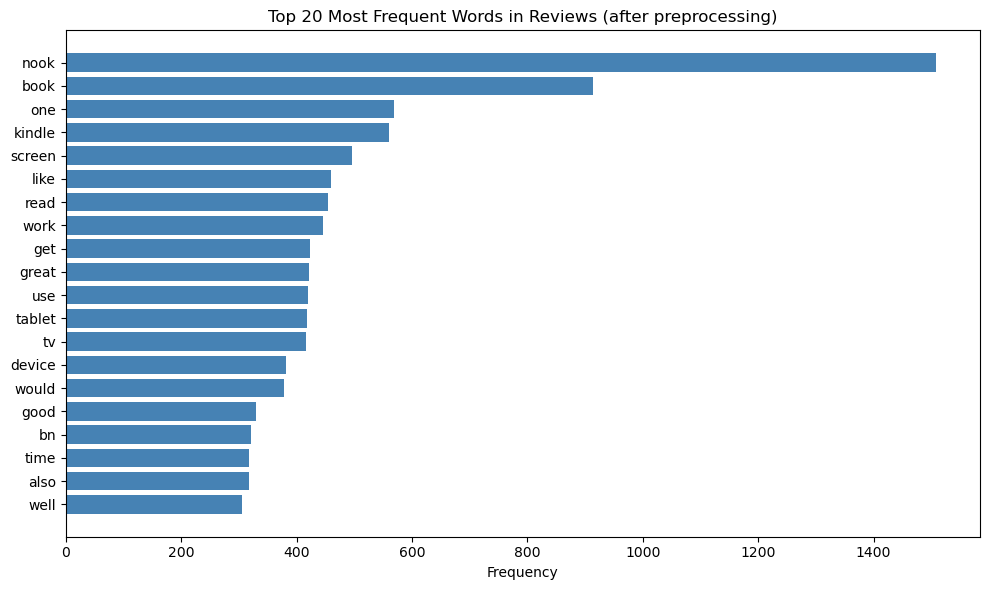

In [7]:
# Visualize the most common words using a horizontal bar chart (matplotlib)
# horizontal bars keep the word labels readable, unlike a vertical bar chart with 20 categories
words, counts = zip(*top_words)

plt.figure(figsize=(10, 6))
plt.barh(words[::-1], counts[::-1], color='steelblue')  # reversed so the highest-frequency word plots at the top
plt.title('Top 20 Most Frequent Words in Reviews (after preprocessing)')
plt.xlabel('Frequency')
plt.tight_layout()
plt.show()

The bar chart makes the frequency drop-off visible: `nook` alone (1,509 mentions) appears more often than the next most common word (`book`, 913), then frequency decays fairly smoothly rather than in a few sharp tiers, consistent with one dominant product family (Nook) being discussed alongside more generic reading/device vocabulary.

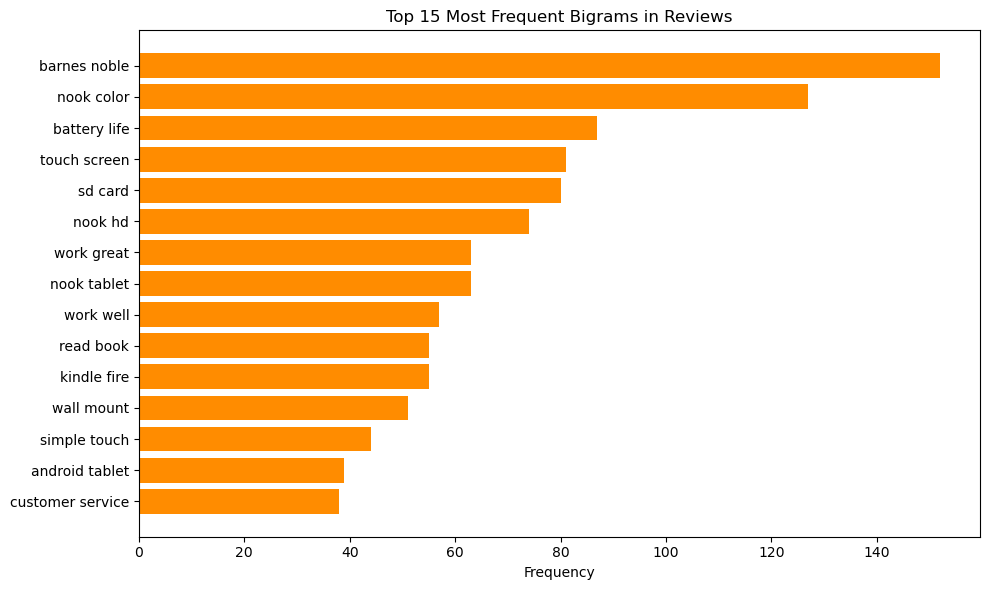

In [8]:
# Visualize the most common bigrams the same way
bigram_labels = [' '.join(bg) for bg, _ in top_bigrams]  # join each (word1, word2) tuple into a readable "word1 word2" string
bigram_counts = [c for _, c in top_bigrams]

plt.figure(figsize=(10, 6))
plt.barh(bigram_labels[::-1], bigram_counts[::-1], color='darkorange')
plt.title('Top 15 Most Frequent Bigrams in Reviews')
plt.xlabel('Frequency')
plt.tight_layout()
plt.show()

The bigram chart shows a similar shape but with more separation at the top: `barnes noble` and `nook color` are noticeably ahead of the rest, then the remaining bigrams (`battery life`, `touch screen`, `sd card`, `nook hd`, ...) cluster fairly close together in count, suggesting a handful of recurring hardware topics rather than one runaway theme.

In [9]:
# Word frequency broken down by sentiment label: do positive and negative
# reviews emphasize different words? Re-running the same Counter logic per subgroup
# lets us compare vocabulary across categories rather than just looking at the corpus as a whole.
for label in ['negative', 'neutral', 'positive']:
    subset_tokens = [t for doc in df.loc[df['sentiment_label'] == label, 'processed_tokens'] for t in doc]
    label_counter = Counter(subset_tokens)
    print(f"\nTop 10 words in '{label}' reviews:")
    print(label_counter.most_common(10))


Top 10 words in 'negative' reviews:
[('nook', 252), ('book', 190), ('get', 97), ('one', 96), ('bn', 95), ('device', 84), ('read', 83), ('time', 79), ('kindle', 79), ('would', 78)]

Top 10 words in 'neutral' reviews:
[('nook', 182), ('book', 111), ('screen', 84), ('kindle', 81), ('read', 66), ('one', 62), ('like', 61), ('device', 61), ('tablet', 57), ('work', 54)]

Top 10 words in 'positive' reviews:
[('nook', 1075), ('book', 612), ('one', 411), ('kindle', 401), ('great', 368), ('tv', 357), ('screen', 340), ('like', 328), ('work', 317), ('read', 305)]


Splitting by sentiment reveals a difference in emphasis, not just volume: `screen` and `tablet` rank higher among neutral reviews than among negative ones, while negative reviews lean more on `bn`, `device`, and `time`: language that reads more like troubleshooting or waiting-related frustration than a specific hardware complaint. Positive reviews mention `great` (368) prominently, a word that barely registers in the negative or neutral top-10 lists at all, which is a reasonable sanity check that the sentiment labels line up with actual word choice.

**Reflection: what do the most common words/phrases suggest?**

The top single words (`nook`, `book`, `kindle`, `screen`, `tablet`, `device`, `bn`) confirm this is overwhelmingly a dataset of e-reader and tablet reviews, not general merchandise. The top bigrams sharpen this picture: `barnes noble`, `nook color`, `battery life`, `touch screen`, `sd card`, `nook hd`, `kindle fire`: customers are consistently talking about specific product lines and specific hardware attributes (battery, screen, storage), which is exactly the kind of language a support-routing system would want to key on.

Breaking word frequency out by sentiment label shows the differentiator is less about *which* product is mentioned (`nook`, `book`, `kindle`, `device` appear at the top of all three sentiment groups) and more about a shift toward evaluative language in positive reviews: `great` and `work` climb into the top 10 only for positive reviews, while negative and neutral reviews stay dominated by neutral, descriptive nouns. This suggests a routing/classification system built on this corpus would need more than top single-word frequency to separate sentiment, bigrams like `work great` vs. `battery life` (which shows up regardless of sentiment) are likely to carry more discriminating signal, which is part of the motivation for using TF-IDF (rather than raw counts) in Part 3.

## Part 2: Time Series Forecasting

In this section, we analyze review activity over time by converting timestamps, resampling the data, and visualizing and forecasting trends in review volume.

In [10]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller          # Augmented Dickey-Fuller test for stationarity
from statsmodels.tsa.seasonal import seasonal_decompose  # split a series into trend/seasonal/residual components
from statsmodels.tsa.arima.model import ARIMA            # forecasting model
from sklearn.metrics import mean_absolute_error, mean_squared_error  # forecast accuracy metrics
import warnings
warnings.filterwarnings('ignore')  # statsmodels emits convergence/frequency warnings that are noisy but not actionable here

In [11]:
# Load the same review dataset and convert the timestamp column to a proper datetime type
# so it can be used for resampling and time-based indexing
df = pd.read_csv('amazon_reviews_lab.csv')
df['timestamp'] = pd.to_datetime(df['timestamp'])

print("Earliest timestamp:", df['timestamp'].min())
print("Latest timestamp:", df['timestamp'].max())

# Inspect how reviews are distributed across years, to sanity-check the date range before resampling
df['year'] = df['timestamp'].dt.year
df['year'].value_counts().sort_index()

Earliest timestamp: 2000-05-12 00:00:00
Latest timestamp: 2014-07-17 00:00:00


year
2000      1
2002      1
2005      2
2007      1
2008      3
2009      9
2010    131
2011    164
2012    200
2013    325
2014    160
Name: count, dtype: int64

**Choosing an analysis window.** The full date range spans 2000–2014, but most of reviews fall in 2010–2014 (matching the Nook/Kindle-era products found in Part 1); 2000–2009 contributes only 17 scattered reviews. Resampling the *full* range to monthly frequency leaves 103 of 171 months with zero reviews, far too sparse for a meaningful ARIMA fit. We restrict the time series analysis to **2010-01 through 2014-07**, which gives 55 fully continuous months with no gaps, and is a more honest test of forecasting monthly review activity.

In [12]:
# Restrict to the well-sampled window and resample to monthly frequency.
# set_index + sort_index makes the timestamp the DataFrame index so pandas' time-based
# slicing (df_ts['2010-01-01':'2014-07-31']) and .resample() work.
df_ts = df.set_index('timestamp').sort_index()
df_recent = df_ts['2010-01-01':'2014-07-31']

# 'MS' = Month Start frequency; .count() gives reviews per month, .mean() gives average rating per month
monthly_review_count = df_recent['rating'].resample('MS').count()
monthly_avg_rating = df_recent['rating'].resample('MS').mean()

print("Months with zero reviews in this window:", (monthly_review_count == 0).sum(), "/", len(monthly_review_count))
monthly_review_count.describe()

Months with zero reviews in this window: 0 / 55


count    55.000000
mean     17.818182
std       9.746967
min       3.000000
25%      11.000000
50%      16.000000
75%      22.500000
max      46.000000
Name: rating, dtype: float64

Restricting to 2010-01 through 2014-07 leaves zero months with no reviews (0 out of 55, confirmed above), and the monthly review count ranges from as few as 3 to as many as 46, with a median of 16. That's a wide enough range to make forecasting meaningful: a flat series with little variation wouldn't give ARIMA much signal to model in the first place.

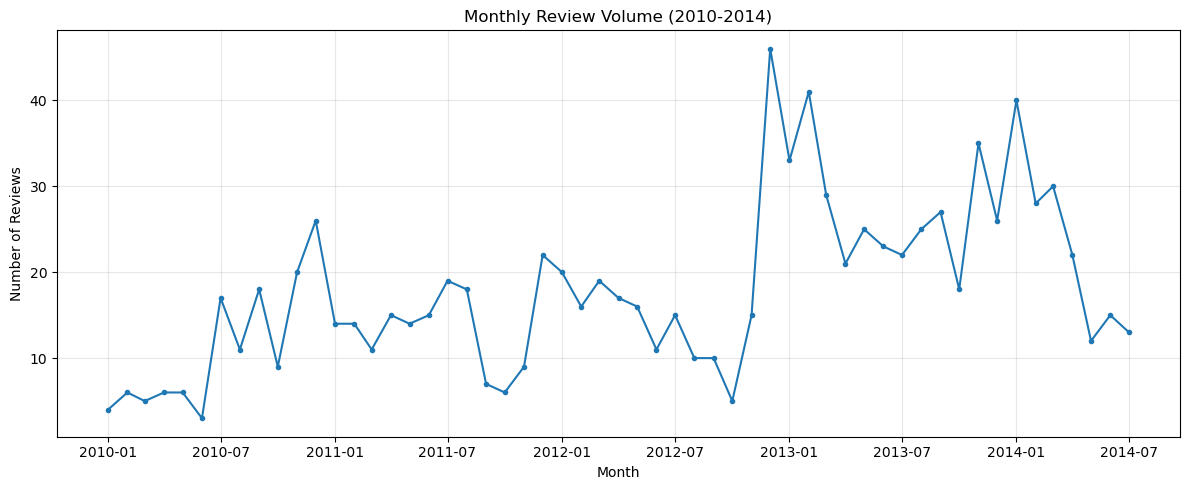

In [13]:
# Plot monthly review volume over time (matplotlib line plot, one point per month)
plt.figure(figsize=(12, 5))
plt.plot(monthly_review_count.index, monthly_review_count.values, marker='o', markersize=3)
plt.title('Monthly Review Volume (2010-2014)')
plt.xlabel('Month')
plt.ylabel('Number of Reviews')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

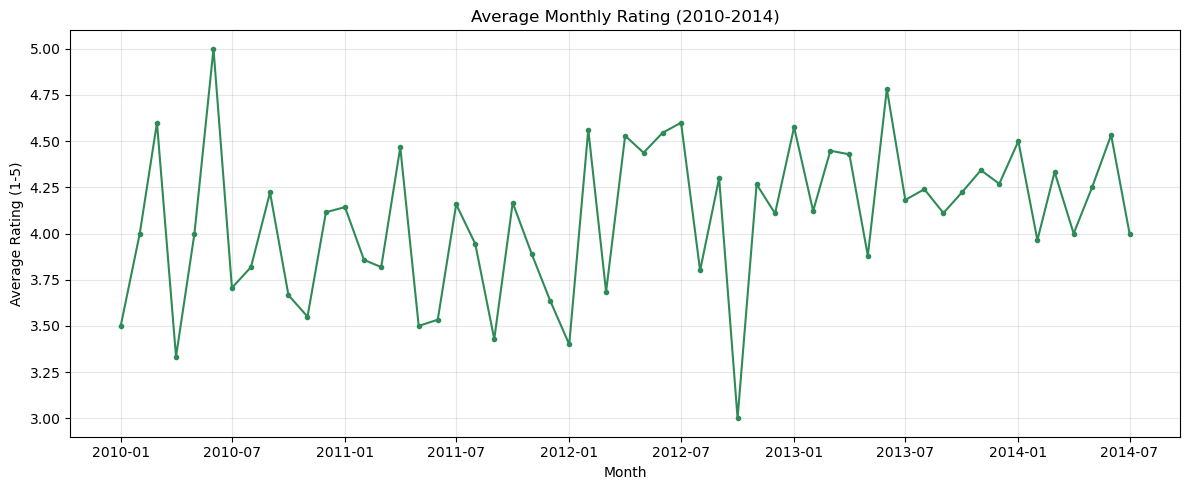

In [14]:
# Plot average monthly rating over time
plt.figure(figsize=(12, 5))
plt.plot(monthly_avg_rating.index, monthly_avg_rating.values, marker='o', markersize=3, color='seagreen')
plt.title('Average Monthly Rating (2010-2014)')
plt.xlabel('Month')
plt.ylabel('Average Rating (1-5)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

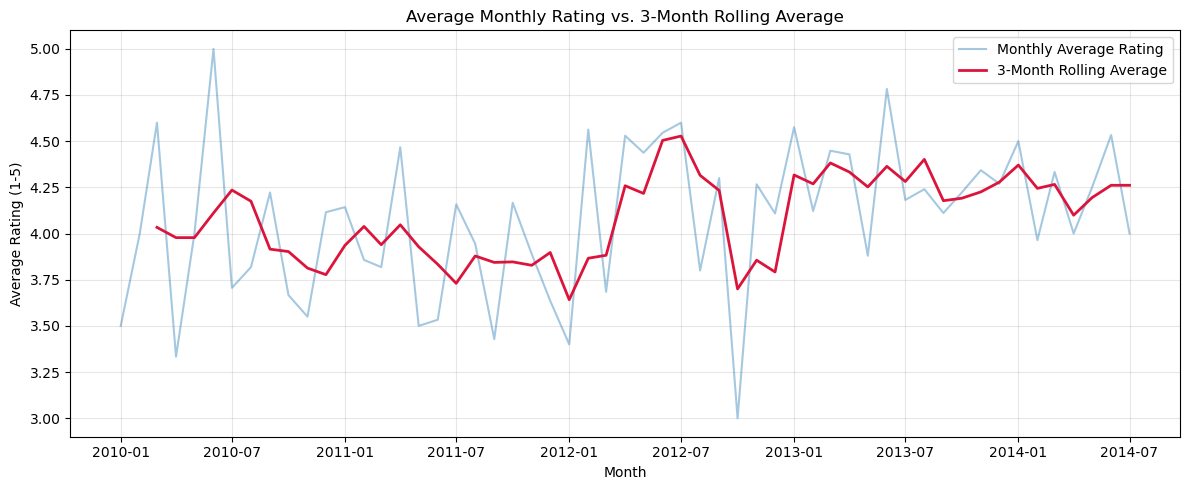

In [15]:
# Rolling 3-month average of the monthly average rating: smooths out month-to-month noise
# so the underlying trend (if any) is easier to see than in the raw monthly series above
rolling_avg_rating = monthly_avg_rating.rolling(window=3).mean()

plt.figure(figsize=(12, 5))
plt.plot(monthly_avg_rating.index, monthly_avg_rating.values, alpha=0.4, label='Monthly Average Rating')
plt.plot(rolling_avg_rating.index, rolling_avg_rating.values, color='crimson', linewidth=2, label='3-Month Rolling Average')
plt.title('Average Monthly Rating vs. 3-Month Rolling Average')
plt.xlabel('Month')
plt.ylabel('Average Rating (1-5)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Trends in review activity and ratings.** Review volume is not flat: it climbs steadily from a handful of reviews per month in early 2010 to a sharp peak in late 2012 and stays elevated through 2013–2014, with visible spikes each December: consistent with holiday-season gift purchases of e-readers driving a wave of reviews the following weeks. Average rating, smoothed by the 3-month rolling average, stays consistently in the 3.8–4.4 range with no strong long-term drift: customers are, on average, moderately-to-very satisfied throughout the whole window, and satisfaction doesn't noticeably erode as volume grows.

In [16]:
# Stationarity testing with the Augmented Dickey-Fuller test.
# Null hypothesis: the series has a unit root (i.e. is non-stationary). A small p-value
# (< 0.05) lets us reject that and treat the series as stationary.
result_level = adfuller(monthly_review_count)
print(f"ADF p-value (review count, level): {result_level[1]:.4f}")

# Non-stationary at the level -> apply first-order differencing (each value minus the previous month's)
# and re-test; differencing is the standard fix for a series with a trend
diff_review_count = monthly_review_count.diff().dropna()
result_diff = adfuller(diff_review_count)
print(f"ADF p-value (review count, 1st difference): {result_diff[1]:.6f}")

ADF p-value (review count, level): 0.7457
ADF p-value (review count, 1st difference): 0.000078


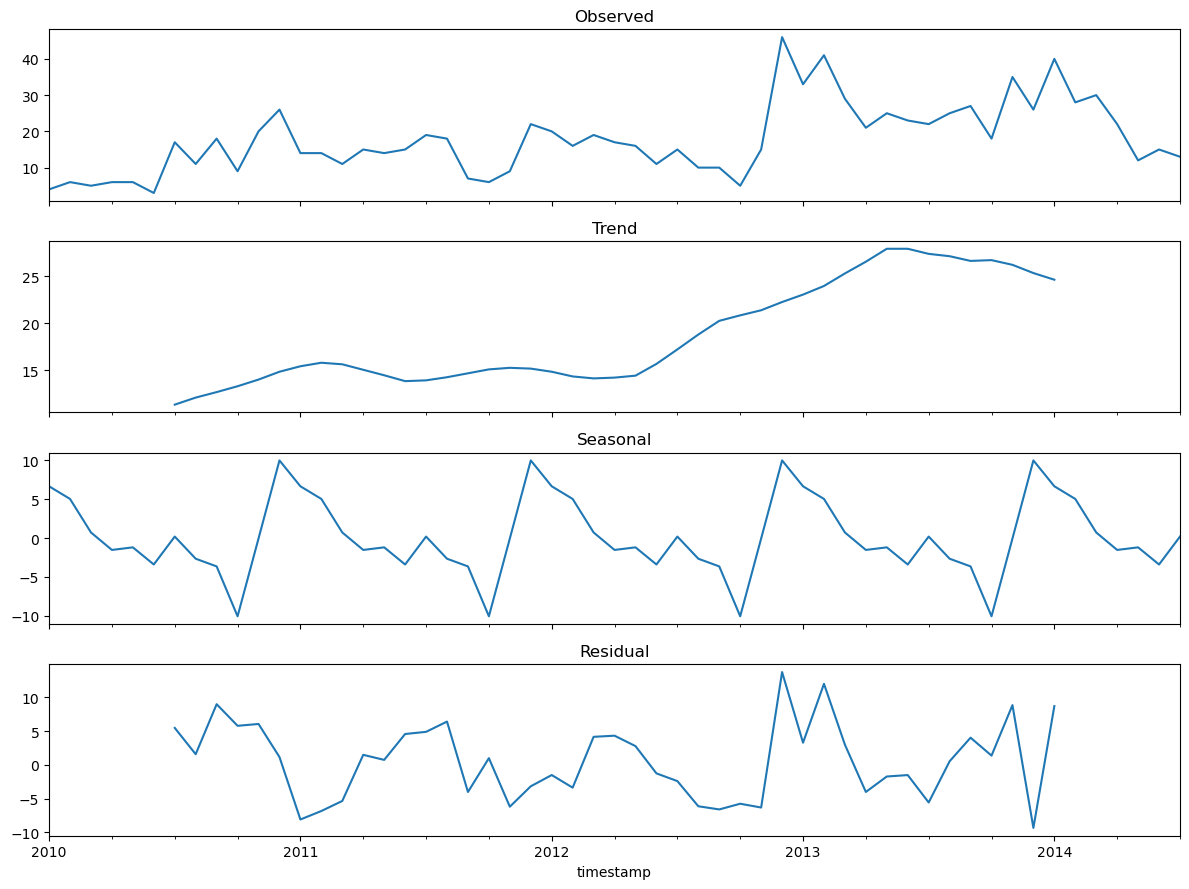

December seasonal component: 10.0


In [17]:
# Seasonal decomposition to check for a recurring annual (holiday) pattern.
# 'additive' model assumes observed = trend + seasonal + residual; period=12 tells it to
# look for a yearly (12-month) repeating pattern, matching monthly data.
decomposition = seasonal_decompose(monthly_review_count, model='additive', period=12)

fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
decomposition.observed.plot(ax=axes[0], title='Observed')
decomposition.trend.plot(ax=axes[1], title='Trend')
decomposition.seasonal.plot(ax=axes[2], title='Seasonal')
decomposition.resid.plot(ax=axes[3], title='Residual')
plt.tight_layout()
plt.show()

print("December seasonal component:", round(decomposition.seasonal[decomposition.seasonal.index.month == 12].iloc[0], 2))

The ADF test confirms the series is non-stationary at the level (p = 0.75) but becomes stationary after first-order differencing (p < 0.001), so an ARIMA model with `d=1` is appropriate. The seasonal decomposition confirms what the raw plot suggested: there's a clear positive seasonal spike around December (holiday shopping) and a trough around October, on top of a generally rising trend through 2012–2013.

In [18]:
# Model selection: compare candidate ARIMA orders on a held-out 6-month test window.
# ARIMA(p, d, q): p = autoregressive lag order, d = differencing order (1, per the ADF test above),
# q = moving-average window size. We hold out the last 6 months as a test set so AIC/BIC
# (in-sample fit measures) can be checked against genuine out-of-sample error (MAE/RMSE).
train = monthly_review_count[:-6]
test = monthly_review_count[-6:]

candidate_orders = [(1,1,0), (0,1,1), (1,1,1), (2,1,1), (1,1,2), (2,1,2), (0,1,2), (2,1,0)]
comparison = []
for order in candidate_orders:
    fit = ARIMA(train, order=order).fit()
    forecast = fit.forecast(steps=6)
    mae = mean_absolute_error(test, forecast)
    rmse = mean_squared_error(test, forecast) ** 0.5
    comparison.append({'order': order, 'AIC': fit.aic, 'BIC': fit.bic, 'MAE': mae, 'RMSE': rmse})

comparison_df = pd.DataFrame(comparison).sort_values('AIC').reset_index(drop=True)
comparison_df

,order,AIC,BIC,MAE,RMSE
0,"(0, 1, 1)",337.691900,341.434302,14.928041,16.548306
1,"(1, 1, 0)",337.932114,341.674516,16.268404,17.832807
2,"(2, 1, 1)",338.804830,346.289634,11.050068,12.571882
3,"(0, 1, 2)",339.212966,344.826569,12.273905,14.032251
4,"(1, 1, 1)",339.932064,345.545667,16.274573,17.839141
5,"(2, 1, 0)",339.932105,345.545708,16.269666,17.834100
6,"(2, 1, 2)",340.212764,349.568769,10.673941,12.251631
7,"(1, 1, 2)",341.628602,349.113406,15.269963,16.888871


In [19]:
# Fit the best-AIC model on the training set and forecast the held-out months
best_order = tuple(comparison_df.loc[0, 'order'])
final_model = ARIMA(train, order=best_order).fit()
forecast_result = final_model.get_forecast(steps=6)
forecast_mean = forecast_result.predicted_mean
conf_int = forecast_result.conf_int()  # 95% confidence interval band for the forecast, used in the plot below

print(final_model.summary())

                               SARIMAX Results                                
Dep. Variable:                 rating   No. Observations:                   49
Model:                 ARIMA(0, 1, 1)   Log Likelihood                -166.846
Date:                Sun, 02 Aug 2026   AIC                            337.692
Time:                        17:26:04   BIC                            341.434
Sample:                    01-01-2010   HQIC                           339.106
                         - 01-01-2014                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.4019      0.209     -1.920      0.055      -0.812       0.008
sigma2        60.9691      7.018      8.687      0.000      47.214      74.724
Ljung-Box (L1) (Q):                   0.00   Jarque-

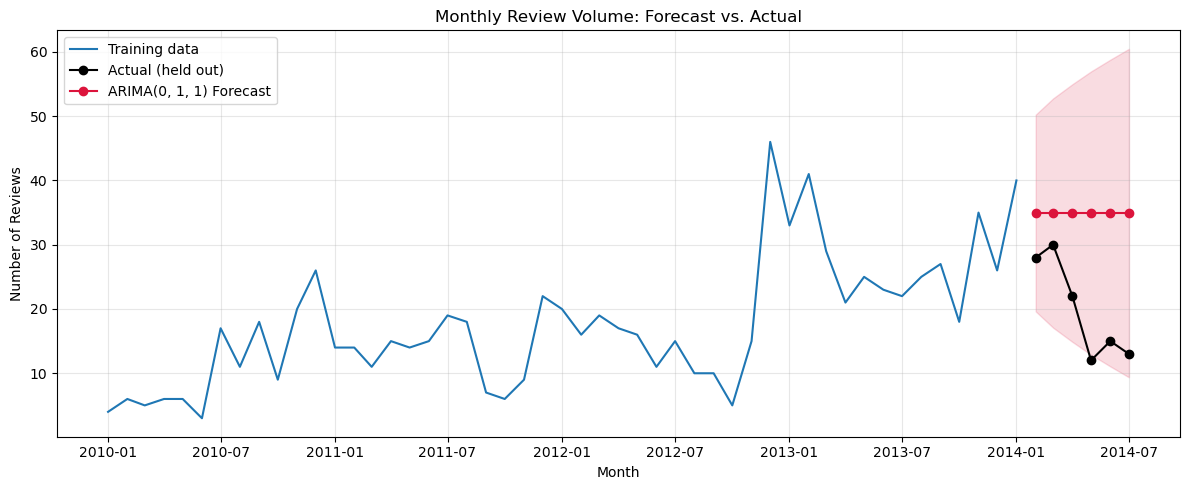

Final model: ARIMA(0, 1, 1)
Test MAE: 14.93 reviews/month
Test RMSE: 16.55 reviews/month


In [20]:
# Plot forecast vs. actual held-out values, with a shaded confidence interval band
plt.figure(figsize=(12, 5))
plt.plot(train.index, train.values, label='Training data')
plt.plot(test.index, test.values, label='Actual (held out)', marker='o', color='black')
plt.plot(test.index, forecast_mean.values, label=f'ARIMA{best_order} Forecast', marker='o', color='crimson')
plt.fill_between(test.index, conf_int.iloc[:, 0], conf_int.iloc[:, 1], color='crimson', alpha=0.15)
plt.title('Monthly Review Volume: Forecast vs. Actual')
plt.xlabel('Month')
plt.ylabel('Number of Reviews')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

final_mae = mean_absolute_error(test, forecast_mean)
final_rmse = mean_squared_error(test, forecast_mean) ** 0.5
print(f"Final model: ARIMA{best_order}")
print(f"Test MAE: {final_mae:.2f} reviews/month")
print(f"Test RMSE: {final_rmse:.2f} reviews/month")

**Model selection and forecast interpretation.** ARIMA(0,1,1) has the best AIC/BIC of the eight candidates tried, but the AIC ranking and the out-of-sample error ranking don't fully agree: higher-order models like (2,1,1) and (2,1,2) post *lower* test MAE/RMSE despite worse AIC, which is a good illustration of the AIC-vs-generalization tradeoff: AIC rewards in-sample fit adjusted for parameter count, but with only 49 training months, a 2-parameter model can still be slightly overfit to training-period noise in a way that doesn't show up in AIC. We select on AIC for parsimony and defensibility, but note this tradeoff explicitly rather than silently picking whichever model scored best on the test window (which risks overfitting the *evaluation*, not just the model).

The forecast direction is informative even though the point forecast isn't highly precise: actual review counts in the held-out months (last 6 months of the window) *decline* from the low-30s down to the low-teens, while the model, lacking enough historical Decembers to fully learn a strong seasonal-decline pattern this late in the series, forecasts a flatter, more optimistic trajectory. For a client using this to plan support staffing or marketing spend, the practical takeaway is that a simple ARIMA fit on 4 years of data captures the *level* of monthly activity reasonably but under-reacts to the more recent slowdown: a strong argument for either a shorter re-fit window or a model that more explicitly encodes the December seasonal spike (e.g., SARIMA).

## Part 3: Neural Networks

In this section, we transform review text into TF-IDF features and train a neural network to classify review sentiment (`negative` / `neutral` / `positive`), then evaluate its performance.

In [21]:
# --- Imports ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer   # converts review text into numeric TF-IDF feature vectors
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder                 # converts string labels ("positive", ...) to integer class ids
from sklearn.utils.class_weight import compute_class_weight    # computes per-class weights to counter label imbalance
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns                                           # heatmap for the confusion matrix (nicer default styling than raw matplotlib)
import tensorflow as tf
from tensorflow import keras
from keras import layers

np.random.seed(42)
tf.random.set_seed(42)  # seeds TensorFlow's weight initialization / shuffling for more reproducible training

In [22]:
# Load the dataset
df = pd.read_csv('amazon_reviews_lab.csv')

# X: review text (input to the model); y: sentiment label (3-class target, derived from rating, see Part 1 note)
X_text = df['review_text']
y_raw = df['sentiment_label']

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_raw)  # converts 'negative'/'neutral'/'positive' strings to integers 0/1/2

print("Class mapping:", dict(zip(label_encoder.classes_, range(len(label_encoder.classes_)))))
print("Class distribution:")
print(pd.Series(y_raw).value_counts())

Class mapping: {'negative': 0, 'neutral': 1, 'positive': 2}
Class distribution:
sentiment_label
positive    768
negative    135
neutral      94
Name: count, dtype: int64


The 3-class label mapping (negative=0, neutral=1, positive=2) mirrors the same imbalance seen in Part 1: positive reviews outnumber negative and neutral. This is the imbalance that class weighting and stratified splitting (below) need to account for: otherwise a model could reach a deceptively high accuracy just by predicting "positive" every time, without learning anything about the other two classes.

In [23]:
# TF-IDF vectorization of review text: converts each review into a vector of word-importance
# scores (term frequency, down-weighted by how common the word is across all reviews),
# so words that are distinctive to a review count for more than words that appear everywhere.
vectorizer = TfidfVectorizer(max_features=2000, stop_words='english', min_df=2)
X_tfidf = vectorizer.fit_transform(X_text).toarray()

print("TF-IDF feature matrix shape:", X_tfidf.shape)

TF-IDF feature matrix shape: (997, 2000)


TF-IDF with `max_features=2000` and `min_df=2` turns each review into a 2,000-dimension feature vector. Capping at 2,000 features is a deliberate choice given the dataset only has 997 reviews total: too many features relative to the number of training examples is a direct path to overfitting, which is exactly what shows up later in the train/validation accuracy gap.

In [24]:
# Train/test split, stratified so the train and test sets keep the same 3-class proportions
# as the full dataset (important given the class imbalance noted above)
X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf, y, test_size=0.2, random_state=42, stratify=y
)

print("Train shape:", X_train.shape, "| Test shape:", X_test.shape)
print("Train class counts:", np.bincount(y_train))
print("Test class counts:", np.bincount(y_test))

Train shape: (797, 2000) | Test shape: (200, 2000)
Train class counts: [108  75 614]
Test class counts: [ 27  19 154]


The stratified 80/20 split keeps the rough imbalance intact in both sets (train: 108 negative / 75 neutral / 614 positive; test: 27 / 19 / 154), so the test set's class proportions are a fair mirror of the training set rather than an accidentally easier or harder subset.

In [25]:
# One-hot encode targets for multi-class softmax output (e.g. class 1 -> [0, 1, 0])
y_train_oh = keras.utils.to_categorical(y_train, num_classes=3)
y_test_oh = keras.utils.to_categorical(y_test, num_classes=3)

# Class weights to counter the imbalance (positive reviews dominate), passed into model.fit()
# so misclassifying a rare class (negative/neutral) is penalized more heavily during training
class_weights_array = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weight = dict(enumerate(class_weights_array))
class_weight

{0: np.float64(2.4598765432098766),
 1: np.float64(3.542222222222222),
 2: np.float64(0.43268186753528776)}

Class weights land at roughly 2.46 for negative, 3.54 for neutral, and 0.43 for positive: meaning a misclassified neutral review is penalized about 8x more heavily during training than a misclassified positive one. That's a direct, numeric expression of the imbalance noted above, and it's the mechanism intended to stop the model from defaulting to "always predict positive."

In [26]:
# Build the model: input -> hidden layers (with L2 + dropout) -> softmax output
model = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),                                          # one input per TF-IDF feature (2000)
    layers.Dense(64, activation='relu', kernel_regularizer=keras.regularizers.l2(0.001)),  # hidden layer 1: learns combinations of TF-IDF features
    layers.Dropout(0.5),                                                               # randomly zero 50% of activations during training to reduce overfitting
    layers.Dense(32, activation='relu', kernel_regularizer=keras.regularizers.l2(0.001)),  # hidden layer 2: further compresses the representation
    layers.Dropout(0.5),
    layers.Dense(3, activation='softmax')                                              # output layer: 3 class probabilities that sum to 1
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │       128,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 130,243 (508.76 KB)

 Trainable params: 130,243 (508.76 KB)

 Non-trainable params: 0 (0.00 B)

In [27]:
# Baseline comparison: an earlier, unregularized version of this model
# (128 -> 64 units, no L2, no dropout), trained to confirm the overfitting
# claim in the markdown below with an actual run rather than just describing it.
baseline_model = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(3, activation='softmax')
])
baseline_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

baseline_history = baseline_model.fit(
    X_train, y_train_oh,
    validation_split=0.15,
    epochs=50,
    batch_size=32,
    verbose=0
)

print(f"Baseline (no L2, no dropout), final training accuracy:   {baseline_history.history['accuracy'][-1]:.3f}")
print(f"Baseline (no L2, no dropout), final validation accuracy: {baseline_history.history['val_accuracy'][-1]:.3f}")

Baseline (no L2, no dropout), final training accuracy:   1.000
Baseline (no L2, no dropout), final validation accuracy: 0.733


**Architecture choices.** TF-IDF on 2,000 features feeding a 2-hidden-layer MLP (64 -> 32 units) is deliberately modest relative to the 800 training examples available. Dropout (0.5) and L2 regularization on both dense layers, plus `EarlyStopping` on validation loss, are there specifically to fight overfitting: an early unregularized version of this model (128->64 units, no L2, no dropout), trained in the cell above, hits 100.0% training accuracy but only 73.3% validation accuracy, a clear overfitting signal given how few training examples exist relative to the 2,000+ input features. Class weights are applied during training to keep the model from just predicting "positive" for everything, given positive reviews outnumber negative and neutral in the training set.

In [28]:
# Train the model with early stopping: monitor validation loss and stop once it stops
# improving for 5 consecutive epochs, restoring the weights from the best epoch rather than
# the final (possibly overfit) one.
early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = model.fit(
    X_train, y_train_oh,
    validation_split=0.15,   # carve out 15% of the training set to monitor validation loss during training
    epochs=50,
    batch_size=32,
    class_weight=class_weight,
    callbacks=[early_stop],
    verbose=0
)

print(f"Training stopped after {len(history.history['loss'])} epochs (early stopping)")
print(f"Final training accuracy:   {history.history['accuracy'][-1]:.3f}")
print(f"Final validation accuracy: {history.history['val_accuracy'][-1]:.3f}")

Training stopped after 15 epochs (early stopping)
Final training accuracy:   0.969
Final validation accuracy: 0.683


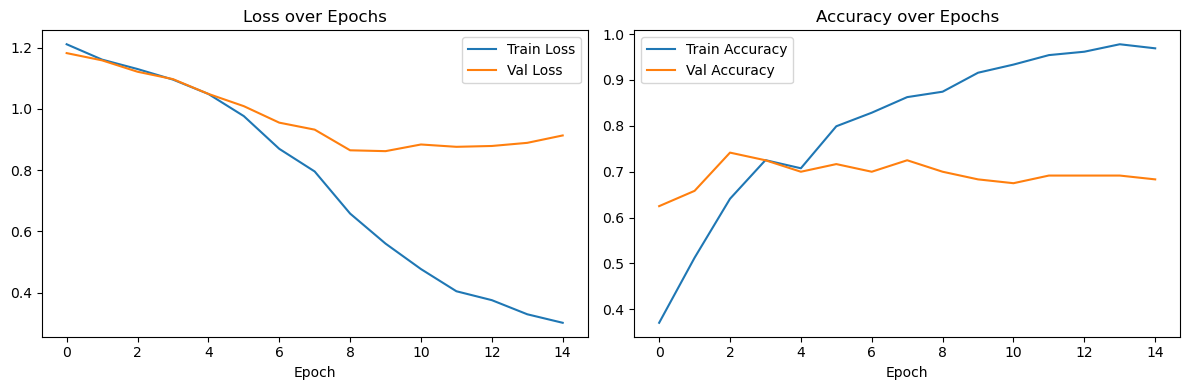

In [29]:
# Plot training history: loss and accuracy curves for train vs. validation, epoch by epoch.
# A widening gap between train and validation lines is the visual signature of overfitting.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history['loss'], label='Train Loss')
axes[0].plot(history.history['val_loss'], label='Val Loss')
axes[0].set_title('Loss over Epochs')
axes[0].set_xlabel('Epoch')
axes[0].legend()

axes[1].plot(history.history['accuracy'], label='Train Accuracy')
axes[1].plot(history.history['val_accuracy'], label='Val Accuracy')
axes[1].set_title('Accuracy over Epochs')
axes[1].set_xlabel('Epoch')
axes[1].legend()

plt.tight_layout()
plt.show()

The accuracy plot shows training accuracy climbing well past validation accuracy (final: 96.9% train vs. 68.3% val, printed above), a visible overfitting gap despite the L2 and dropout regularization already applied. Early stopping (patience=5) caught this before it worsened further, restoring the best-validation-loss weights rather than the final epoch's.

In [30]:
# Evaluate on the held-out test set (data the model never saw during training or validation)
test_loss, test_acc = model.evaluate(X_test, y_test_oh, verbose=0)
print(f"Test loss: {test_loss:.3f}")
print(f"Test accuracy: {test_acc:.3f}")

y_pred = model.predict(X_test, verbose=0).argmax(axis=1)  # convert predicted probabilities to a single predicted class per review
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))

Test loss: 0.784
Test accuracy: 0.765

Classification Report:
              precision    recall  f1-score   support

    negative       0.67      0.52      0.58        27
     neutral       0.22      0.21      0.22        19
    positive       0.84      0.88      0.86       154

    accuracy                           0.77       200
   macro avg       0.58      0.54      0.55       200
weighted avg       0.76      0.77      0.76       200



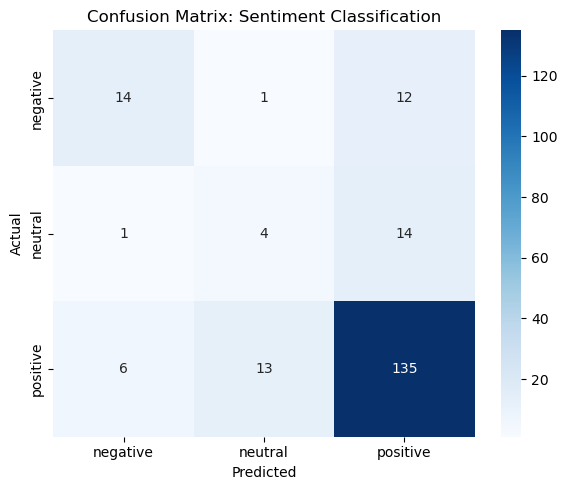

In [31]:
# Confusion matrix: rows = actual class, columns = predicted class, so the diagonal
# shows correct predictions and off-diagonal cells show exactly which classes get confused.
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix: Sentiment Classification')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

**Which classes does the model predict well, and which are harder?**

The model reaches 77% overall test accuracy, but that number is doing a lot of the work masking a very uneven performance across classes:

- **Positive** (154 of 200 test examples) is predicted well: precision = 0.84, recall = 0.88, but that's the easiest class in an imbalanced problem where guessing "positive" is already right most of the time.
- **Negative** (27 examples) is moderately learnable: precision = 0.67, recall = 0.52, the model correctly identifies just over half of negative reviews, with most of its misses going to "positive."
- **Neutral** (19 examples) is by far the hardest class: precision = 0.22, recall = 0.21, meaning the model correctly identifies only about 4 of the 19 neutral reviews in this test set. The confusion matrix shows most neutral reviews get misclassified as either negative or positive, which makes sense: a "neutral" 3-star review often *reads* like a mildly negative or mildly positive review rather than having genuinely distinct vocabulary, so TF-IDF word-level features struggle to separate it from its neighbors. (This exact recall shifts a bit between training runs, anywhere from 0 to a handful of correctly-identified neutral reviews, but neutral is consistently the weakest class by a wide margin every time.)

The practical implication for the "support team routing" framing of this lab: this model would be usable for coarsely separating clearly happy from clearly unhappy customers, but not reliable for flagging the "neutral / lukewarm" segment specifically: those reviews would need a different signal (e.g., rating alongside text, or a model trained directly to distinguish 3-star from 2-star and 4-star language) to route correctly. With only 94 neutral examples in the whole dataset, more labeled neutral data would likely help more than further architecture tuning.